# Feature Engineering

**Objetivo.** Partir de `matches_clean.csv` (generado por `eda.ipynb`, 36,150 partidos de 2014/15 a 2025/26) y construir el dataset de modelado: forma reciente de cada equipo, mercado, calidad de plantilla y los conjuntos de features **F1** (sin NaN) y **F2** (completo). Al final se mide cuánto aporta cada bloque con validación cruzada temporal.

**Convención del notebook.** Cada celda de código va precedida por una celda de texto (qué vamos a hacer y por qué) y seguida por otra (qué encontramos y qué decidimos).

| Paso | Qué hace |
|---|---|
| 0 | Carga de datos (limpios, estadísticas observadas, cuotas observadas, calentamiento 2013/14) |
| 1 | Forma de los últimos 5 partidos con calentamiento y ventana acolchada |
| 2 | Verificación independiente del historial y mapa de NaN |
| 3 | Eliminación de columnas post-partido y correlación inicial |
| 4 | Mercado: consenso de probabilidades implícitas |
| 5 | Poda por correlación |
| 6 | Calidad de plantilla |
| 7 | Ranking de Mutual Information |
| 8 | Conjuntos F1/F2, validaciones finales y exportación |
| 9 | Aporte de cada bloque (validación cruzada temporal) |

**Referencia.** Zheng & Casari, *Feature Engineering for Machine Learning* (cap. 2: sanity checks numéricos y selección *filter*; cap. 5: *back-off* hacia el prior, estadísticas acotadas y control de leakage).

## Paso 0 — Carga de datos

**Qué vamos a hacer.** Cargar cuatro fuentes alineadas fila a fila:

1. `matches_clean.csv`: dataset limpio del EDA (squad, bloques de cuotas imputadas por KNN).
2. `matches_sq.csv` (columnas de cuotas): cuotas **observadas**, sin imputar, para construir el mercado y el backtest.
3. `matches_sq.csv` (columnas de partido): goles y estadísticas **observadas**, con NaN donde la fuente no las publica.
4. `matches_warmup.csv`: temporada 2013/14, solo para dar historial a los equipos en 2014/15.

**Por qué.** El KNN del EDA rellenaba tiros, córners, faltas y tarjetas incluso donde la fuente no los publica (sin nada con qué estimar, devolvía casi constantes). Para las features usamos los valores observados.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice')

CUOTAS = ['B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSCH', 'PSCD', 'PSCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA', 'BFH', 'BFD', 'BFA', '1XBH', '1XBD', '1XBA', 'BFEH', 'BFED', 'BFEA', 'BFE>2.5', 'BFE<2.5', 'BFEAHH', 'BFEAHA', 'BFCH', 'BFCD', 'BFCA', '1XBCH', '1XBCD', '1XBCA', 'BFECH', 'BFECD', 'BFECA', 'BFEC>2.5', 'BFEC<2.5', 'BFECAHH', 'BFECAHA', 'BFDH', 'BFDD', 'BFDA', 'BMGMH', 'BMGMD', 'BMGMA', 'BVH', 'BVD', 'BVA', 'CLH', 'CLD', 'CLA', 'BFDCH', 'BFDCD', 'BFDCA', 'BMGMCH', 'BMGMCD', 'BMGMCA', 'BVCH', 'BVCD', 'BVCA', 'CLCH', 'CLCD', 'CLCA', 'LBCH', 'LBCD', 'LBCA', 'SJH', 'SJD', 'SJA']

df_clean = pd.read_csv("../data/matches_clean.csv")

# Cuotas observadas (sin imputar), misma fila que matches_clean
ODDS_RAW_COLS = ['B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'PSCH', 'PSCD', 'PSCA']
raw_odds = pd.read_csv("../data/matches_sq.csv", usecols=['Date', 'HomeTeam', 'AwayTeam'] + ODDS_RAW_COLS)

# Estadisticas observadas (con NaN) y temporada de calentamiento
STAT_COLS = ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']
_u = ['Div', 'Season', 'Date', 'HomeTeam', 'AwayTeam', 'FTR'] + STAT_COLS
raw_stats = pd.read_csv("../data/matches_sq.csv", usecols=_u)
warm = pd.read_csv("../data/matches_warmup.csv", usecols=_u)

for d in (raw_odds, raw_stats):
    assert len(d) == len(df_clean)
    assert (d['Date'].values == df_clean['Date'].values).all() and (d['HomeTeam'].values == df_clean['HomeTeam'].values).all()

print('matches_clean:', df_clean.shape)
print('partidos modelables:', len(raw_stats), '| temporadas:', sorted(raw_stats['Season'].unique()))
print('partidos de calentamiento (solo historial):', len(warm), '| temporada', warm['Season'].unique().tolist())

matches_clean: (36150, 80)
partidos modelables: 36150 | temporadas: [np.int64(1415), np.int64(1516), np.int64(1617), np.int64(1718), np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324), np.int64(2425), np.int64(2526)]
partidos de calentamiento (solo historial): 2918 | temporada [1314]


**Hallazgo.** Se cargaron 36,150 partidos modelables (12 temporadas, 2014/15–2025/26) y 2,918 partidos de calentamiento (2013/14). Las tres fuentes están alineadas fila a fila con `matches_clean` (comprobado con fecha y equipo local).

**Decisión.** Las features de forma y el mercado se construyen desde las columnas **observadas** (`matches_sq.csv`), no desde las imputadas por KNN en `matches_clean`.

## Paso 1 — Forma de los últimos 5 partidos (con calentamiento y ventana acolchada)

**Qué vamos a hacer.** Convertir cada partido en dos registros (local y visitante) con las estadísticas desde el lado del equipo, y calcular para cada uno la media de sus **últimos 5 partidos sin incluir el actual**. El resultado se une de vuelta como `H_*_5` (forma del local) y `A_*_5` (forma del visitante).

**Decisiones de diseño** (cap. 5 de Zheng & Casari: *back-off* hacia el prior; no fabricar datos):

- **Calentamiento:** los partidos de 2013/14 entran al historial pero no se modelan. Así la jornada 1 de 2014/15 ya tiene forma real.
- **Estadísticas observadas:** si la fuente no publica tiros/córners/faltas/tarjetas para un partido, el valor es NaN y no se inventa.
- **Ventana acolchada:** si en los últimos 5 partidos hay solo `n` valores observados, los `5−n` restantes valen la media de su liga **estrictamente anterior a la fecha** (solo valores observados). Una ventana completa no cambia. Si la liga aún no tiene ningún valor observado de esa estadística, el resultado es NaN.
- Goles, puntos, victorias y portería a cero salen de `FTHG/FTAG/FTR`, que siempre existen.

In [3]:
# Base: partidos de calentamiento + partidos modelables, en orden cronologico
base = pd.concat([warm.assign(is_warm=True), raw_stats.assign(is_warm=False)], ignore_index=True)
for col in STAT_COLS:
    base[col] = pd.to_numeric(base[col], errors='coerce')
base['match_id'] = np.where(base['is_warm'], -1, np.arange(len(base)) - len(warm))   # fila en df_clean (-1 = calentamiento)
base['Date_dt'] = pd.to_datetime(base['Date'], dayfirst=True, format='mixed', errors='coerce')
assert base['Date_dt'].notna().all(), 'fechas sin parsear'
base = base.sort_values(['Date_dt', 'is_warm', 'match_id'], ascending=[True, False, True]).reset_index(drop=True)
base['seq'] = np.arange(len(base))

ev_rows = []
for lado, col in [('H', 'HomeTeam'), ('A', 'AwayTeam')]:
    e = base.copy()
    local = e['HomeTeam'] == e[col]
    e['Team'] = e[col]
    e['lado'] = lado
    e['GF'] = np.where(local, e['FTHG'], e['FTAG'])
    e['GA'] = np.where(local, e['FTAG'], e['FTHG'])
    ganador = 'H' if lado == 'H' else 'A'
    e['WinRate'] = (e['FTR'] == ganador).astype(float)
    e['Pts'] = np.select([e['FTR'] == ganador, e['FTR'] == 'D'], [3, 1], 0)
    e['SGF'], e['SGA'] = np.where(local, e['HS'], e['AS']), np.where(local, e['AS'], e['HS'])
    e['SOTF'], e['SOTA'] = np.where(local, e['HST'], e['AST']), np.where(local, e['AST'], e['HST'])
    e['CF'], e['CA'] = np.where(local, e['HC'], e['AC']), np.where(local, e['AC'], e['HC'])
    e['FF'], e['FA'] = np.where(local, e['HF'], e['AF']), np.where(local, e['AF'], e['HF'])
    e['CardF'] = np.where(local, e['HY'] + e['HR'], e['AY'] + e['AR'])      # NaN si falta alguna
    e['CardA'] = np.where(local, e['AY'] + e['AR'], e['HY'] + e['HR'])
    e['CS'] = (e['GA'] == 0).astype(float)
    ev_rows.append(e[['match_id', 'seq', 'Team', 'Div', 'Date_dt', 'lado', 'is_warm',
                      'GF', 'GA', 'Pts', 'WinRate', 'SGF', 'SGA', 'SOTF', 'SOTA', 'CF', 'CA', 'FF', 'FA', 'CardF', 'CardA', 'CS']])
ev = pd.concat(ev_rows, ignore_index=True).sort_values(['Team', 'seq']).reset_index(drop=True)

ROLL = ['GF','GA','Pts','WinRate','SGF','SGA','SOTF','SOTA','CF','CA','FF','FA','CardF','CardA','CS']
N_WIN = 5
for f in ROLL:
    val = ev[f]
    obs = val.notna().astype(float)
    suma = val.fillna(0.0).groupby(ev['Team']).transform(lambda s: s.shift(1).rolling(N_WIN, min_periods=1).sum()).fillna(0.0)
    n_obs = obs.groupby(ev['Team']).transform(lambda s: s.shift(1).rolling(N_WIN, min_periods=1).sum()).fillna(0.0)
    # prior: media de la liga con partidos estrictamente anteriores a la fecha (solo valores observados)
    dia = ev.assign(_v=val.fillna(0.0), _o=obs).groupby(['Div', 'Date_dt'])[['_v', '_o']].sum().reset_index().sort_values(['Div', 'Date_dt'])
    dia['cs'] = dia.groupby('Div')['_v'].transform(lambda s: s.cumsum().shift(1))
    dia['cn'] = dia.groupby('Div')['_o'].transform(lambda s: s.cumsum().shift(1))
    dia['prior'] = dia['cs'] / dia['cn'].replace(0, np.nan)
    prior = ev[['Div', 'Date_dt']].merge(dia[['Div', 'Date_dt', 'prior']], on=['Div', 'Date_dt'], how='left')['prior'].to_numpy()
    pad = N_WIN - n_obs.to_numpy()
    out = (suma.to_numpy() + pad * np.nan_to_num(prior)) / N_WIN
    # NaN solo si hacen falta huecos y la liga aun no tiene ningun valor observado (nada que usar como prior)
    ev[f + '_5'] = np.where((pad > 0) & np.isnan(prior), np.nan, out)

modelable = ev[~ev['is_warm']]
print('equipo-partido modelables:', len(modelable), '| de calentamiento:', int(ev['is_warm'].sum()))
for f in ['GF', 'Pts', 'SGF', 'CardF']:
    print(f'  {f}_5 NaN:', int(modelable[f + '_5'].isna().sum()))

df_clean['match_id'] = np.arange(len(df_clean))
h = modelable[modelable['lado'] == 'H'][['match_id'] + [f + '_5' for f in ROLL]]
h.columns = ['match_id'] + ['H_' + f + '_5' for f in ROLL]
a = modelable[modelable['lado'] == 'A'][['match_id'] + [f + '_5' for f in ROLL]]
a.columns = ['match_id'] + ['A_' + f + '_5' for f in ROLL]
df_clean = df_clean.merge(h, on='match_id', how='left').merge(a, on='match_id', how='left').drop(columns=['match_id'])
print('Features rolling agregadas:', 2 * len(ROLL), '| filas:', len(df_clean))


equipo-partido modelables: 72300 | de calentamiento: 5836
  GF_5 NaN: 0
  Pts_5 NaN: 0
  SGF_5 NaN: 6958
  CardF_5 NaN: 6958
Features rolling agregadas: 30 | filas: 36150


**Hallazgo.**

- Se generaron 72,300 registros equipo-partido modelables (2 por partido) y 5,836 de calentamiento.
- Las features de goles, puntos, victorias y portería a cero quedan **sin NaN** (`GF_5` y `Pts_5`: 0 NaN).
- Las de tiros, córners, faltas y tarjetas tienen **6,958 registros equipo-partido en NaN** (≈3,500 partidos por 2 lados): son los partidos en que la fuente no publica esas estadísticas (se detalla en el Paso 2b).

**Decisión.** Mantener la ventana acolchada: no cambia ninguna ventana completa y evita tanto fabricar datos como mirar el futuro.

## Paso 2 — Verificación independiente del historial

**Qué vamos a hacer.** Comprobar que el cálculo anterior es correcto sin reutilizar su código: para 300 partidos elegidos al azar recalculamos `H_GF_5` (goles del local) y `A_Pts_5` (puntos del visitante) directamente desde la tabla de partidos, tomando los 5 partidos previos de cada equipo estrictamente anteriores a la fecha. Además mostramos tres partidos de las primeras jornadas de 2014/15 para confirmar que usan historial de 2013/14.

**Por qué.** Es el punto donde un error silencioso (mirar el futuro, ventana mal alineada) invalidaría todo el modelado.

In [4]:
def pts(r, team):
    if r.FTR == 'D':
        return 1
    return 3 if (r.FTR == 'H') == (r.HomeTeam == team) else 0

def gf(r, team):
    return r.FTHG if r.HomeTeam == team else r.FTAG

rng = np.random.default_rng(0)
cand = base[~base['is_warm']].sample(1500, random_state=0)
comprobados, dif_max = 0, 0.0
for r in cand.itertuples():
    for team, col, fn in [(r.HomeTeam, 'H_GF_5', gf), (r.AwayTeam, 'A_Pts_5', pts)]:
        prev = base[((base['HomeTeam'] == team) | (base['AwayTeam'] == team)) & (base['Date_dt'] < r.Date_dt)].sort_values('seq').tail(5)
        if len(prev) < 5:
            continue
        esperado = np.mean([fn(p, team) for p in prev.itertuples()])
        obtenido = df_clean.loc[r.match_id, col]
        dif_max = max(dif_max, abs(esperado - obtenido))
        comprobados += 1
    if comprobados >= 600:
        break
print(f'comprobaciones: {comprobados} | diferencia maxima: {dif_max:.2e}')
assert comprobados > 300 and dif_max < 1e-9

# Arranque de 2014/15: cuantos partidos previos (de 2013/14) tenian los equipos
primeros = base[(~base['is_warm'])].nsmallest(3, 'seq')
for r in primeros.itertuples():
    for team in (r.HomeTeam, r.AwayTeam):
        n = int((((base['HomeTeam'] == team) | (base['AwayTeam'] == team)) & (base['Date_dt'] < r.Date_dt)).sum())
        print(f'{r.Div} {r.Date}: {team:<18} partidos previos disponibles = {n}')
# Fraccion de partidos de 2014/15 con ventana completa gracias al calentamiento
ev['n_prev'] = ev.groupby('Team').cumcount()           # partidos previos del equipo en el historial (incluye 2013/14)
m15 = ev[(~ev['is_warm']) & (ev['Date_dt'] < '2015-07-01')]
print('equipo-partido de 2014/15:', len(m15), '| con ventana completa (>=5 previos):', f"{(m15['n_prev'] >= 5).mean():.1%}")
print('sin ningun partido previo (equipos que ascienden desde fuera del dataset):', f"{(m15['n_prev'] == 0).mean():.1%}")

comprobaciones: 600 | diferencia maxima: 0.00e+00
B1 25/07/14: Standard           partidos previos disponibles = 30
B1 25/07/14: Charleroi          partidos previos disponibles = 30
B1 26/07/14: Cercle Brugge      partidos previos disponibles = 30
B1 26/07/14: Gent               partidos previos disponibles = 30
B1 26/07/14: Lierse             partidos previos disponibles = 30
B1 26/07/14: Oostende           partidos previos disponibles = 30
equipo-partido de 2014/15: 5968 | con ventana completa (>=5 previos): 97.9%
sin ningun partido previo (equipos que ascienden desde fuera del dataset): 0.4%


**Hallazgo.**

- **600 comprobaciones independientes** (300 partidos × 2 features) con diferencia máxima **0.0**: el historial calculado coincide exactamente con el recálculo a mano.
- Con el calentamiento, el **97.9%** de los registros equipo-partido de 2014/15 tiene ventana completa (≥5 partidos previos). Solo el **0.4%** no tiene ningún partido previo (equipos que ascienden desde fuera del dataset) y usa el prior de su liga.
- Sin el calentamiento, el primer día de cada liga habría tenido que usar la media global (que incluye el futuro) en 20 partidos.

**Decisión.** Conservar la temporada 2013/14 como calentamiento (no se modela ni se evalúa).

### Paso 2b — Mapa de NaN en las estadísticas de partido

**Qué vamos a hacer.** Contar, por liga y temporada, cuántos partidos modelables tienen alguna feature de estadísticas de partido en NaN, para confirmar que el patrón coincide con lo que publica la fuente y no con un error del cálculo.

In [5]:
ROLL5 = [c for c in df_clean.columns if c.endswith('_5')]
COMPLETAS = [p + f + '_5' for p in ('H_', 'A_') for f in ('GF', 'GA', 'Pts', 'WinRate', 'CS')]
ESTAD = [c for c in ROLL5 if c not in COMPLETAS]
assert df_clean[COMPLETAS].notna().all().all(), 'quedan NaN en features de goles/puntos'
assert (df_clean[ROLL5].fillna(0) >= 0).all().all(), 'valores negativos en el rolling'

nan_row = df_clean[ESTAD].isna().any(axis=1)
tabla = (df_clean.assign(nan=nan_row).groupby(['Div', 'Season'])['nan'].sum().unstack(fill_value=0))
tabla = tabla.loc[:, tabla.sum() > 0]
print('features completas con NaN:', int(df_clean[COMPLETAS].isna().sum().sum()))
print('partidos con alguna estadistica en NaN:', int(nan_row.sum()), f'({nan_row.mean():.1%})')
print('\nPartidos con NaN por liga y temporada (solo filas/columnas con NaN):')
print(tabla[tabla.sum(axis=1) > 0].to_string())

# Que columnas del crudo explican el patron
crudo = raw_stats.groupby(['Div', 'Season'])[['HS', 'HST', 'HC', 'HF', 'HY', 'HR']].apply(lambda d: d.notna().mean().round(2))
print('\nProporcion observada en el CRUDO (B1/N1/P1/T1, 2014/15-2018/19):')
print(crudo.loc[(['B1', 'N1', 'P1', 'T1']), :].query("Season <= 1819").to_string())

features completas con NaN: 0
partidos con alguna estadistica en NaN: 3959 (11.0%)

Partidos con NaN por liga y temporada (solo filas/columnas con NaN):
Season  1415  1516  1617  1718  1819  1920
Div                                       
B1       240   240   240   240   240     1
N1       306   306   306     1     0     0
P1       306   306   306     2     0     0
T1       306   306   306     1     0     0

Proporcion observada en el CRUDO (B1/N1/P1/T1, 2014/15-2018/19):
             HS  HST   HC   HF   HY   HR
Div Season                              
B1  1415    0.0  0.0  0.0  0.0  0.0  0.0
    1516    0.0  0.0  0.0  0.0  0.0  0.0
    1617    0.0  0.0  0.0  0.0  0.0  0.0
    1718    1.0  1.0  1.0  0.0  1.0  1.0
    1819    1.0  1.0  1.0  0.0  1.0  1.0
N1  1415    0.0  0.0  0.0  0.0  0.0  0.0
    1516    0.0  0.0  0.0  0.0  0.0  0.0
    1617    0.0  0.0  0.0  0.0  0.0  0.0
    1718    1.0  1.0  1.0  1.0  1.0  1.0
    1819    1.0  1.0  1.0  1.0  1.0  1.0
P1  1415    0.0  0.0  0.0  0.0 

**Hallazgo.** El patrón de NaN coincide exactamente con lo que publica la fuente:

| Liga | Temporadas | Qué falta | Partidos con NaN |
|---|---|---|---|
| B1, N1, P1, T1 | 2014/15–2016/17 | **Todas** las estadísticas de partido | 3,474 |
| B1 | 2017/18 y 2018/19 | Solo faltas (`HF`/`AF`) | 480 |
| Varias | 2017/18–2019/20 | Primer día de la liga con estadísticas (sin prior todavía) | 5 |

En total **3,959 partidos (11.0%)** tienen alguna estadística de partido en NaN; las 10 features de goles/puntos/portería a cero tienen 0 NaN.

**Decisión.** **No imputar.** Las filas con NaN se conservan:

- **F2** las incluye con NaN y la usan los modelos que toleran valores faltantes (árboles).
- **F1** excluye esas columnas y la usan regresión logística, SVM y MLP.

Este hallazgo debe aparecer en la sección 3 del informe (calidad de datos).

## Paso 3 — Eliminar columnas post-partido y correlación inicial

**Qué vamos a hacer.** Quitar del dataset las columnas que solo se conocen **después** del partido (goles, tiros, córners, faltas y tarjetas del propio partido). Su único papel era alimentar el historial del paso 1. Luego mirar la correlación entre las variables numéricas para decidir qué bloques son redundantes.

**Por qué.** Dejar cualquiera de ellas como feature introduciría el resultado en el modelo (leakage trivial).

FTR conservado como target: True
<class 'pandas.DataFrame'>
RangeIndex: 36150 entries, 0 to 36149
Data columns (total 93 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Div                        36150 non-null  str    
 1   Date                       36150 non-null  str    
 2   HomeTeam                   36150 non-null  str    
 3   AwayTeam                   36150 non-null  str    
 4   FTR                        36150 non-null  str    
 5   B365H                      36150 non-null  float64
 6   B365D                      36150 non-null  float64
 7   B365A                      36150 non-null  float64
 8   BWH                        36150 non-null  float64
 9   BWD                        36150 non-null  float64
 10  BWA                        36150 non-null  float64
 11  PSH                        36150 non-null  float64
 12  PSD                        36150 non-null  float64
 13  PSA                     

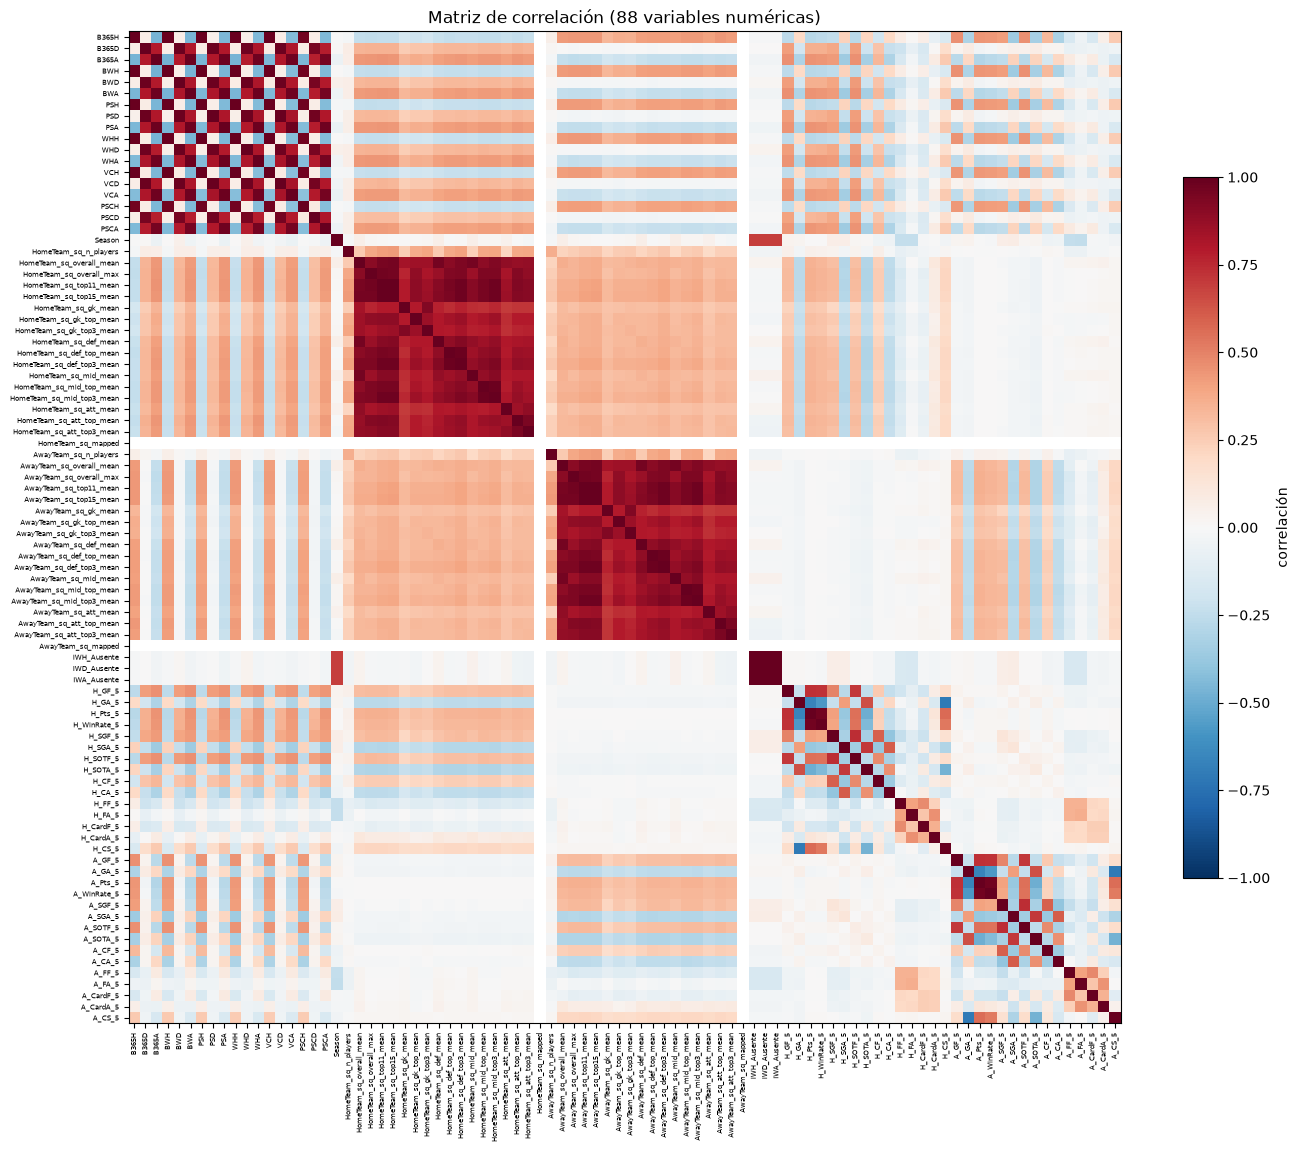

Pares con |r| > 0.95: 75 de 7744
IWH_Ausente             IWA_Ausente               1.000
IWD_Ausente             IWA_Ausente               1.000
IWH_Ausente             IWD_Ausente               1.000
AwayTeam_sq_top11_mean  AwayTeam_sq_top15_mean    0.999
HomeTeam_sq_top11_mean  HomeTeam_sq_top15_mean    0.999
PSH                     VCH                       0.991
BWH                     WHH                       0.990
B365H                   PSH                       0.989
                        BWH                       0.989
BWH                     PSH                       0.989
WHH                     VCH                       0.989
PSH                     WHH                       0.988


In [6]:
finalizar = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST',
                    'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']

columnas_a_borrar = [col for col in finalizar if col in df_clean.columns]
df_clean = df_clean.drop(columns=columnas_a_borrar)
print('FTR conservado como target:', 'FTR' in df_clean.columns)
df_clean.info()

num = df_clean.select_dtypes(include=[np.number]).columns
corr = df_clean[num].corr()
fig, ax = plt.subplots(figsize=(16, 13))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, shrink=0.7, label='correlación')
ax.set_title(f'Matriz de correlación ({len(corr)} variables numéricas)')
plt.show()

tri = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print('Pares con |r| > 0.95:', int((tri > 0.95).sum()), 'de', len(tri))
print(tri.head(12).round(3).to_string())

**Hallazgo.**

- Se eliminaron 17 columnas post-partido (`FTR` se conserva como target).
- Hay **75 pares con |r| > 0.95** de 7,744: las banderas `IWH/IWD/IWA_Ausente` (r = 1.0), `top11_mean` con `top15_mean` (0.999) y las cuotas de distintas casas entre sí (0.98–0.99). Eso confirma la multicolinealidad del mercado.

**Decisión.** Construir un único consenso de mercado (Paso 4) y podar por correlación (Paso 5). Las banderas `*_Ausente` se descartan: reflejan la temporada en que la fuente dejó de publicar una cuota, no una señal del partido.

## Paso 4 — Mercado: consenso de probabilidades implícitas

**Qué vamos a hacer.** Convertir las cuotas de apertura en probabilidades y combinarlas entre casas.

1. Para cada casa (B365, BW, PS, WH) con las tres cuotas observadas: `p = (1/o) / Σ(1/o)`. La suma de `1/o` supera 1 por el margen de la casa; normalizar lo elimina.
2. Promediar **solo entre las casas observadas** (`nanmean`). No se usa ninguna cuota imputada por KNN.
3. Añadir `MKT_logit = ln(pH/pA)` (lineal en log-odds, útil para modelos lineales) y `MKT_margin` (overround medio).
4. Excluir del dataset de modelado los partidos sin cuota en ninguna casa (ya aportaron al historial de sus equipos).

**Por qué.** `AvgH/D/A` solo existen desde 2019/20; las cuotas de casas clásicas cubren todas las temporadas. Las cuotas de cierre (PSC*) **no** son features: se exportan aparte para el backtest.

In [7]:
TARGET = 'FTR'
META = ['Date', 'Date_dt', 'HomeTeam', 'AwayTeam', 'Div', 'Season']

# --- Mercado: consenso de probabilidades implicitas sobre cuotas OBSERVADAS (apertura) ---
BOOKS = [('B365H', 'B365D', 'B365A'), ('BWH', 'BWD', 'BWA'), ('PSH', 'PSD', 'PSA'), ('WHH', 'WHD', 'WHA')]
_P, _M = [], []
for h, d, a in BOOKS:
    inv = 1.0 / raw_odds[[h, d, a]].to_numpy(dtype=float)      # NaN si falta alguna de las 3
    tot = inv.sum(axis=1, keepdims=True)
    _P.append(inv / tot)
    _M.append(tot.ravel() - 1.0)
_P, _M = np.stack(_P), np.stack(_M)                             # (casas, filas, 3) / (casas, filas)
n_casas = (~np.isnan(_M)).sum(axis=0)
has_odds = n_casas > 0
with np.errstate(all='ignore'):
    P = np.nanmean(_P, axis=0)
    MARGIN = np.nanmean(_M, axis=0)
print('partidos sin ninguna cuota:', int((~has_odds).sum()), '| casas por partido (min/mediana):', int(n_casas[has_odds].min()), int(np.median(n_casas[has_odds])))

df_clean['MKT_pH'], df_clean['MKT_pD'], df_clean['MKT_pA'] = P[:, 0], P[:, 1], P[:, 2]
df_clean['MKT_logit'] = np.log(P[:, 0] / P[:, 2])
df_clean['MKT_margin'] = MARGIN

# --- Se descartan los partidos sin mercado (ya aportaron al rolling de sus equipos) ---
keep = has_odds
df_clean = df_clean.loc[keep].reset_index(drop=True)
raw_odds = raw_odds.loc[keep].reset_index(drop=True)
assert df_clean[['MKT_pH', 'MKT_pD', 'MKT_pA', 'MKT_logit', 'MKT_margin']].notna().all().all()
print('MKT_margin min/mediana/max:', df_clean['MKT_margin'].min().round(3), df_clean['MKT_margin'].median().round(3), df_clean['MKT_margin'].max().round(3))

# --- Cuotas para el backtest (NO son features): observadas, sin imputar ---
odds_bt = pd.concat([df_clean[['Div', 'Season', 'Date', 'HomeTeam', 'AwayTeam', TARGET, 'MKT_pH', 'MKT_pD', 'MKT_pA']],
                     raw_odds[['B365H', 'B365D', 'B365A', 'PSCH', 'PSCD', 'PSCA']]], axis=1)

FEATURES = [c for c in df_clean.columns if c not in META + [TARGET]]
df_final = df_clean[FEATURES + [TARGET, 'Date', 'HomeTeam', 'AwayTeam', 'Div', 'Season']].copy()
df_final['Date_dt'] = pd.to_datetime(df_final['Date'], dayfirst=True, format='mixed', errors='coerce')

cuotas_purge = [c for c in CUOTAS if c in df_final.columns]
ausentes = [c for c in df_final.columns if c.endswith('_Ausente')]
df_final = df_final.drop(columns=cuotas_purge + ausentes)
print('df_final:', df_final.shape, '| cuotas crudas eliminadas:', len(cuotas_purge), '| banderas *_Ausente eliminadas:', len(ausentes))


partidos sin ninguna cuota: 31 | casas por partido (min/mediana): 1 4
MKT_margin min/mediana/max: 0.023 0.052 0.181
df_final: (36119, 78) | cuotas crudas eliminadas: 18 | banderas *_Ausente eliminadas: 3


**Hallazgo.**

- Se excluyeron **31 partidos sin ninguna cuota**: 29 de la Süper Lig 2022/23 y 2 de la Serie A. Quedan 36,119 filas.
- Casas observadas por partido: mínimo 1, mediana 4.
- `MKT_margin` va de **0.023 a 0.181** (mediana 0.052). Todos los márgenes son positivos, como corresponde a casas reales (la versión anterior, con KNN, producía márgenes de hasta −0.17).

**Decisión.** Usar el consenso de probabilidades implícitas sobre cuotas observadas. El dataset de modelado pasa a 36,119 × 78 antes de la poda.

## Paso 5 — Poda por correlación

**Qué vamos a hacer.** Eliminar features casi duplicadas (|r| > 0.95), conservando primero las del mercado y la plantilla y luego las de forma. La correlación se calcula solo con el primer 80% de los partidos por fecha.

**Por qué.** Cap. 2 de Zheng: el filtrado por correlación es barato y no mira el target, así que no introduce leakage; debe hacerse de forma conservadora.

In [8]:
UMBRAL_CORR = 0.95
corte = df_final['Date_dt'].quantile(0.80)
train_idx = df_final['Date_dt'] <= corte

NUM_FEAT = [c for c in df_final.columns if c not in META + [TARGET]
            and pd.api.types.is_numeric_dtype(df_final[c])]
corr_m = df_final.loc[train_idx, NUM_FEAT].corr().abs()

order = (['MKT_logit', 'MKT_pH', 'MKT_pD', 'MKT_pA', 'MKT_margin',
          'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean']
         + sorted([c for c in NUM_FEAT if c.startswith(('H_', 'A_'))])
         + sorted([c for c in NUM_FEAT if c not in ['MKT_logit', 'MKT_pH', 'MKT_pD', 'MKT_pA', 'MKT_margin',
                   'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean']
                   and not c.startswith(('H_', 'A_'))]))

kept, dropped = [], set()
for c in order:
    if c not in corr_m.columns or c in dropped:
        continue
    kept.append(c)
    for d in NUM_FEAT:
        r = corr_m.loc[c, d]
        if d not in kept and d not in dropped and not (r != r) and r > UMBRAL_CORR:
            dropped.add(d)

drop_list = [d for d in dropped if d in df_final.columns]
df_final = df_final.drop(columns=drop_list)
print('eliminadas por correlación:', len(drop_list))
print('descartadas:', sorted(drop_list))

eliminadas por correlación: 14
descartadas: ['A_WinRate_5', 'AwayTeam_sq_def_top3_mean', 'AwayTeam_sq_mid_top3_mean', 'AwayTeam_sq_overall_max', 'AwayTeam_sq_overall_mean', 'AwayTeam_sq_top15_mean', 'H_WinRate_5', 'HomeTeam_sq_def_top3_mean', 'HomeTeam_sq_mid_top3_mean', 'HomeTeam_sq_overall_max', 'HomeTeam_sq_overall_mean', 'HomeTeam_sq_top15_mean', 'MKT_pA', 'MKT_pH']


**Hallazgo.** Se descartaron 14 features por correlación: `MKT_pH` y `MKT_pA` (redundantes con `MKT_logit`), `H_WinRate_5`/`A_WinRate_5` (redundantes con los puntos) y 8 medidas de plantilla (`overall_mean`, `overall_max`, `top15_mean`, `def_top3`, `mid_top3`, local y visitante).

**Decisión.** Mantener la poda. Es conservadora (umbral 0.95), no usa el target y se calculó con el primer 80% de los partidos.

## Paso 6 — Calidad de plantilla

**Qué vamos a hacer.** De las 17 medidas de plantilla por lado conservar solo la media del once mejor valorado (`top11_mean`), porque las medias por línea (defensa/medio/ataque/porteros) correlacionan 0.88–0.96 con ella. Para el resultado importa más la **ventaja neta**, así que creamos `DIF_sq_top11 = local − visitante` y quitamos la absoluta del visitante.

**Por qué.** Con el mapeo de clubes corregido la cobertura es 100%, así que las banderas `*_sq_mapped` son constantes y se eliminan.

**Limitaciones que dejamos documentadas.** `top11_mean` es el promedio de los 11 jugadores con mejor `overall` del plantel (no el once titular real) y no está normalizado por liga.

In [9]:
KEEP_SQ = {'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean'}
sq_drop = [c for c in df_final.columns if '_sq_' in c and c not in KEEP_SQ]
df_final = df_final.drop(columns=sq_drop)

df_final['DIF_sq_top11'] = df_final['HomeTeam_sq_top11_mean'] - df_final['AwayTeam_sq_top11_mean']
df_final = df_final.drop(columns=['AwayTeam_sq_top11_mean'])
print('squad granulares eliminadas:', len(sq_drop))
print('squad restantes:', [c for c in df_final.columns if '_sq_' in c or c.startswith('DIF_sq_')])

squad granulares eliminadas: 24
squad restantes: ['HomeTeam_sq_top11_mean', 'DIF_sq_top11']


**Hallazgo.** Quedan dos features de plantilla: `HomeTeam_sq_top11_mean` y `DIF_sq_top11`. Se descartaron 24 medidas granulares.

**Decisión.** Conservar solo la ventaja neta y el nivel del local. **Pendiente (no resuelto aquí):** normalizar por liga y usar el once titular real, que requeriría alineaciones que no tenemos.

## Paso 7 — Ranking de Mutual Information

**Qué vamos a hacer.** Calcular `mutual_info_classif` entre cada feature y el resultado, **solo con el primer 80% de los partidos** y, como el estimador no admite NaN, solo con las filas que tienen todas las features observadas.

**Por qué.** MI mide dependencia no lineal con el target. Aquí se usa como **ranking informativo**, no para truncar: la decisión de qué bloques conservar se toma en el Paso 9 con validación cruzada temporal.

In [10]:
from sklearn.feature_selection import mutual_info_classif

NUM_FEAT = [c for c in df_final.columns if c not in META + [TARGET]
            and pd.api.types.is_numeric_dtype(df_final[c])]
assert 'Season' not in NUM_FEAT and not any(c.endswith('_Ausente') for c in NUM_FEAT)
# mutual_info_classif no admite NaN: se calcula sobre las filas de train con todas las features observadas
mask_mi = train_idx & df_final[NUM_FEAT].notna().all(axis=1)
print('filas de train usadas para MI:', int(mask_mi.sum()), 'de', int(train_idx.sum()))
y_cod = df_final.loc[mask_mi, TARGET].map({'H': 0, 'D': 1, 'A': 2}).astype(int)

mi = mutual_info_classif(df_final.loc[mask_mi, NUM_FEAT], y_cod, random_state=42, n_neighbors=3)
mi_serie = pd.Series(mi, index=NUM_FEAT).sort_values(ascending=False)
mi_serie.to_csv('../data/mi_ranking.csv', header=['mi'])

df_final = df_final[NUM_FEAT + [TARGET] + META]
print(f'{len(NUM_FEAT)} features. Ranking MI (solo train):')
print(mi_serie.round(4).to_string())


filas de train usadas para MI: 24939 de 28898
33 features. Ranking MI (solo train):
MKT_logit                 0.0979
DIF_sq_top11              0.0665
A_Pts_5                   0.0270
MKT_pD                    0.0240
HomeTeam_sq_top11_mean    0.0230
H_SGF_5                   0.0226
A_SGF_5                   0.0220
A_SOTF_5                  0.0220
H_Pts_5                   0.0186
A_GF_5                    0.0178
H_SOTF_5                  0.0173
H_GF_5                    0.0169
H_CF_5                    0.0165
H_GA_5                    0.0158
H_SOTA_5                  0.0157
A_SOTA_5                  0.0156
H_SGA_5                   0.0146
A_CA_5                    0.0141
A_GA_5                    0.0116
A_SGA_5                   0.0111
H_CA_5                    0.0099
A_CF_5                    0.0078
H_CS_5                    0.0047
A_CardF_5                 0.0042
A_CardA_5                 0.0035
A_CS_5                    0.0019
MKT_margin                0.0015
H_FF_5                   

**Hallazgo.**

- `MKT_logit` domina con MI = **0.098**, seguido de `DIF_sq_top11` (0.067).
- Todas las features de forma están por debajo de **0.027**, y cinco (`H_FA`, `H_CardA`, `A_FA`, `A_FF`, `H_CardF`) valen ≈ 0.
- Con valores tan bajos, diferencias de 0.00x están dentro del ruido del estimador.
- MI se calculó con 24,939 de 28,898 filas de train (las que no tienen NaN).

**Decisión.** **No truncar por MI.** El ranking se conserva como evidencia descriptiva y la decisión de qué bloques mantener se toma en el Paso 9 con validación cruzada temporal.

## Paso 8 — Conjuntos F1 / F2, validaciones finales y exportación

**Qué vamos a hacer.**

- **F2** = todas las features (algunas con NaN donde la fuente no publica estadísticas de partido). Lo usan los modelos que toleran NaN (árboles).
- **F1** = solo features sin NaN. Lo usan LR, SVM y MLP.
- Validar el dataset final: sin columnas post-partido, sin `Season`/banderas de temporada, rangos plausibles, alineación con `backtest_odds.csv`.
- Exportar `dataset_final.csv`, `backtest_odds.csv`, `feature_sets.json` y `mi_ranking.csv`.

In [11]:
import json
POST = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']
F2 = list(NUM_FEAT)
F1 = [f for f in NUM_FEAT if df_final[f].notna().all()]

# validaciones
assert not set(POST) & set(F2), 'hay columnas post-partido entre las features'
assert 'Season' not in F2 and not any(f.endswith('_Ausente') for f in F2)
assert (df_final[['Date', 'HomeTeam', 'AwayTeam']].values == odds_bt[['Date', 'HomeTeam', 'AwayTeam']].values).all()
assert df_final[F1].notna().all().all()
rangos = df_final[F2].agg(['min', 'max']).T
assert (rangos.loc[[f for f in F2 if f.startswith(('H_', 'A_'))], 'min'] >= 0).all()

json.dump({'F1_sin_nan': F1, 'F2_completo': F2, 'target': TARGET, 'meta': META}, open('../data/feature_sets.json', 'w'), indent=1)
df_final.to_csv("../data/dataset_final.csv", index=False)
odds_bt.to_csv("../data/backtest_odds.csv", index=False)

print('dataset_final:', df_final.shape, '| backtest_odds:', odds_bt.shape)
print('F1:', len(F1), 'features sin NaN:', F1)
print('F2:', len(F2), 'features | con NaN:', len([f for f in F2 if f not in F1]))
print('distribucion del target:', df_final[TARGET].value_counts(normalize=True).round(3).to_dict())

dataset_final: (36119, 40) | backtest_odds: (36119, 15)
F1: 13 features sin NaN: ['HomeTeam_sq_top11_mean', 'H_GF_5', 'H_GA_5', 'H_Pts_5', 'H_CS_5', 'A_GF_5', 'A_GA_5', 'A_Pts_5', 'A_CS_5', 'MKT_pD', 'MKT_logit', 'MKT_margin', 'DIF_sq_top11']
F2: 33 features | con NaN: 20
distribucion del target: {'H': 0.444, 'A': 0.307, 'D': 0.25}


**Hallazgo.**

- `dataset_final.csv`: **36,119 × 40** (33 features + target + metadatos).
- **F1** = 13 features sin NaN. **F2** = 33 features, de las cuales 20 tienen NaN.
- Distribución del target: H = 44.4%, D = 25.0%, A = 30.7%.
- Todas las validaciones pasaron: sin columnas post-partido, sin `Season`/banderas de temporada, rangos plausibles y alineación con `backtest_odds.csv`.

**Decisión.** Congelar este dataset como entrada del modelado.

## Paso 9 — Aporte de cada bloque de features (validación cruzada temporal)

**Qué vamos a hacer.** Responder con datos la pregunta *"¿qué bloques merecen quedarse?"* añadiendo las features por bloques y midiendo el **log loss** fuera de muestra:

| Bloque | Contenido |
|---|---|
| **M** | Mercado (`MKT_logit`, `MKT_pD`, `MKT_margin`) |
| **M+S** | + plantilla (`DIF_sq_top11`, `HomeTeam_sq_top11_mean`) |
| **M+S+G** | + goles/puntos/portería a cero de los últimos 5 partidos (= F1) |
| **M+S+G+E** | + tiros/córners/faltas/tarjetas (= F2, solo árboles) |

**Diseño experimental.**
- *Validación cruzada temporal con ventana expansiva:* para cada temporada de validación (2018/19 … 2025/26) se entrena con todas las temporadas anteriores. Ningún fold ve el futuro.
- *Modelos:* regresión logística (con estandarización dentro del pipeline) y HistGradientBoosting (tolera NaN). Hiperparámetros **fijos y conservadores**, sin tuning: es una medición comparativa, no el modelo final.
- *Referencias:* prior (frecuencias del train) y mercado (`MKT_pH/pD/pA` sin modelo).
- *Métrica:* log loss (primaria) y accuracy. Se reporta media ± desvío entre folds y en cuántos folds el bloque mejora al anterior.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, accuracy_score

y = df_final[TARGET].map({'H': 0, 'D': 1, 'A': 2}).to_numpy()
seas = df_final['Season'].to_numpy()
FOLDS = [s for s in sorted(df_final['Season'].unique()) if s >= 1819]

MKT = [f for f in ['MKT_logit', 'MKT_pD', 'MKT_margin'] if f in F2]
SQ = [f for f in ['DIF_sq_top11', 'HomeTeam_sq_top11_mean'] if f in F2]
FORMA = [f for f in F1 if f.startswith(('H_', 'A_'))]
ESTAD_F = [f for f in F2 if f not in F1]
BLOQUES = {
    'M': MKT,
    'M+S': MKT + SQ,
    'M+S+G (F1)': MKT + SQ + FORMA,
    'M+S+G+E (F2)': MKT + SQ + FORMA + ESTAD_F,
}
print({k: len(v) for k, v in BLOQUES.items()}, '| folds:', FOLDS)

def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
def hgb():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3,
                                          min_samples_leaf=100, l2_regularization=1.0, random_state=42)

filas = []
mk = odds_bt[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()
for s in FOLDS:
    tr, va = seas < s, seas == s
    prior = np.bincount(y[tr], minlength=3) / tr.sum()
    filas.append(dict(fold=s, modelo='prior', bloque='-', ll=log_loss(y[va], np.tile(prior, (va.sum(), 1))), acc=accuracy_score(y[va], np.full(va.sum(), prior.argmax()))))
    filas.append(dict(fold=s, modelo='mercado', bloque='-', ll=log_loss(y[va], mk[va]), acc=accuracy_score(y[va], mk[va].argmax(1))))
    for nombre, cols in BLOQUES.items():
        for modelo, fab in (('LR', lr), ('HGB', hgb)):
            if modelo == 'LR' and df_final[cols].isna().any().any():
                continue                                   # LR no tolera NaN: solo bloques de F1
            m = fab().fit(df_final.loc[tr, cols], y[tr])
            p = m.predict_proba(df_final.loc[va, cols])
            filas.append(dict(fold=s, modelo=modelo, bloque=nombre, ll=log_loss(y[va], p), acc=accuracy_score(y[va], p.argmax(1))))
res = pd.DataFrame(filas)
res.to_csv('../data/ablation_results.csv', index=False)

resumen = res.groupby(['modelo', 'bloque'], sort=False).agg(ll_media=('ll', 'mean'), ll_std=('ll', 'std'), acc_media=('acc', 'mean')).round(4)
print(resumen.to_string())

# En cuantos folds mejora cada bloque respecto al anterior (mismo modelo)
print('\nMejora de log loss respecto al bloque anterior (media y folds en que mejora):')
orden = list(BLOQUES)
for modelo in ('LR', 'HGB'):
    for a, b in zip(orden[:-1], orden[1:]):
        ra = res[(res.modelo == modelo) & (res.bloque == a)].set_index('fold')['ll']
        rb = res[(res.modelo == modelo) & (res.bloque == b)].set_index('fold')['ll']
        if len(ra) and len(rb):
            d = (ra - rb)
            print(f'  {modelo:<3} {a:<14} -> {b:<14}: delta media = {d.mean():+.4f} | mejora en {(d > 0).sum()}/{len(d)} folds')
vs_mkt = res[res.modelo == 'mercado'].set_index('fold')['ll']
for modelo in ('LR', 'HGB'):
    for nombre in BLOQUES:
        r = res[(res.modelo == modelo) & (res.bloque == nombre)].set_index('fold')['ll']
        if len(r):
            d = vs_mkt - r
            print(f'  {modelo:<3} {nombre:<14} vs mercado: delta media = {d.mean():+.4f} | mejora en {(d > 0).sum()}/{len(d)} folds')

{'M': 3, 'M+S': 5, 'M+S+G (F1)': 13, 'M+S+G+E (F2)': 33} | folds: [np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324), np.int64(2425), np.int64(2526)]
                      ll_media  ll_std  acc_media
modelo  bloque                                   
prior   -               1.0726  0.0084     0.4369
mercado -               0.9665  0.0117     0.5383
LR      M               0.9655  0.0127     0.5379
HGB     M               0.9677  0.0126     0.5372
LR      M+S             0.9656  0.0127     0.5384
HGB     M+S             0.9678  0.0130     0.5364
LR      M+S+G (F1)      0.9661  0.0127     0.5388
HGB     M+S+G (F1)      0.9681  0.0131     0.5365
        M+S+G+E (F2)    0.9687  0.0129     0.5363

Mejora de log loss respecto al bloque anterior (media y folds en que mejora):
  LR  M              -> M+S           : delta media = -0.0001 | mejora en 3/8 folds
  LR  M+S            -> M+S+G (F1)    : delta media = -0.0005 | mejora en 0/8 folds
  HGB M 

**Hallazgo.** Log loss medio en 8 folds temporales (2018/19–2025/26):

| Modelo | Bloque | Log loss | Accuracy |
|---|---|---|---|
| Prior | — | 1.0726 | 0.437 |
| Mercado (sin modelo) | — | 0.9665 | 0.538 |
| **LR** | **M** | **0.9655** | 0.538 |
| LR | M+S | 0.9656 | 0.538 |
| LR | M+S+G (F1) | 0.9661 | 0.539 |
| HGB | M | 0.9677 | 0.537 |
| HGB | M+S | 0.9678 | 0.536 |
| HGB | M+S+G (F1) | 0.9681 | 0.537 |
| HGB | M+S+G+E (F2) | 0.9687 | 0.536 |

1. **El mercado concentra casi toda la señal.** El prior (1.0726) queda muy lejos; modelar con las cuotas ya llega a 0.9655.
2. **La plantilla no mejora:** Δ = −0.0001 (mejora en 3/8 folds con LR y 4/8 con HGB).
3. **La forma (goles/puntos) empeora ligeramente:** Δ = −0.0005 con LR (**0/8 folds**) y −0.0003 con HGB.
4. **Las estadísticas de partido tampoco ayudan:** Δ = −0.0006 con HGB (2/8 folds).
5. **LR supera a HGB en todos los bloques** por ≈ 0.002: el modelo más flexible sobreajusta ruido.
6. **LR sobre solo el mercado mejora al mercado crudo en 0.0009** (6/8 folds): es una recalibración, no información nueva.

**Matiz.** Las diferencias entre bloques (≈ 0.0001–0.0006) son mucho menores que la variación entre folds (± 0.012); lo relevante es el signo, que es sistemático (los bloques extra no ayudan). Los hiperparámetros se fijaron sin tuning: es una medición comparativa.

**Decisión.**

- **Se conservan F1 y F2** como entradas del modelado: son necesarias para comparar modelos y responder las preguntas de investigación.
- **No se añaden más features del mismo tipo** (forma por venue, diferencias H−A, normalización por liga) hasta probar con una evaluación barata que aportan algo: la evidencia actual dice que más features de forma no ayudan.
- **Baseline de referencia:** LR sobre el bloque M, junto con el prior y el mercado crudo.

## Resumen de decisiones

| Paso | Decisión | Justificación |
|---|---|---|
| 0 | Usar estadísticas y cuotas **observadas** | El KNN fabricaba constantes donde la fuente no publica datos |
| 1 | Forma de 5 partidos con calentamiento 2013/14 y ventana acolchada | Historial real desde la primera jornada; sin mirar el futuro |
| 2 | Verificar por recálculo independiente | 600 comprobaciones, diferencia 0.0 |
| 2b | **No imputar** estadísticas ausentes; F1 sin NaN, F2 con NaN | 3,959 partidos (11%) sin esas estadísticas en la fuente |
| 3 | Descartar columnas post-partido y banderas `*_Ausente` | Evitar leakage; las banderas son proxies de temporada |
| 4 | Mercado = consenso de probabilidades implícitas observadas; excluir 31 partidos sin cuota | Cobertura completa; márgenes coherentes |
| 5 | Poda por correlación > 0.95 (14 features) | Redundancia; sin leakage |
| 6 | Plantilla: `top11_mean` y `DIF_sq_top11` | Resto de medidas correlacionan 0.88–0.96 |
| 7 | MI como ranking, no como corte | Todas las MI son bajas; decide el Paso 9 |
| 8 | Congelar `dataset_final.csv` (F1: 13, F2: 33) | Entrada del modelado |
| 9 | Ningún bloque supera al mercado por un margen relevante | Ver tabla del Paso 9 |

**Consecuencia para el informe.** La hipótesis (i) (*las cuotas dominan*) está respaldada por los datos; la hipótesis (ii) (*la plantilla aporta señal complementaria*) **no** lo está con estas features y modelos. Ese es un resultado legítimo y debe discutirse en la sección 8 del informe, junto con las limitaciones listadas en el Paso 6.